# 07. Arquitecturas secuenciales con dos salidas

Implementaremos tres alternativas: **LSTM, TCN y CNN-LSTM**, usando las ventanas y etiquetas del paso 06. Todas incorporan modelo de máquina y antigüedad, y generan una respuesta binaria y otra multiclase.

En este paso compararemos su estructura, cantidad de parámetros, formas de entrada y salida, causalidad y cálculo de la pérdida. **Todavía no compararemos su capacidad predictiva:** el entrenamiento completo, las estrategias de desbalance y la evaluación de validación corresponden al próximo paso.

Los modelos están en `arquitecturas_secuenciales.py`; este notebook importa esas mismas clases, explica cómo funcionan y las comprueba. No exporta modelos, métricas ni figuras. No se abre prueba ni se modifican los conjuntos preparados.

## 1. Importar la preparación y las arquitecturas

El módulo de secuencias permite comenzar desde una sesión nueva: no necesitamos que el notebook 06 esté abierto. La semilla es 42 y todas las verificaciones se harán en CPU con cuatro hilos para que puedan reproducirse localmente.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from torch.utils.data import DataLoader, Subset
from IPython.display import display

# Encontrar la raíz del proyecto desde esta carpeta o desde el repositorio.
actual = Path.cwd()
if (actual / "Datos").is_dir():
    ruta_repo = actual
elif (actual.parent / "Datos").is_dir():
    ruta_repo = actual.parent
else:
    raise FileNotFoundError("No se encontró la carpeta Datos.")

# Los dos módulos contienen la implementación compartida, sin duplicarla en el notebook.
for carpeta in ["Preprocesamiento", "Modelación"]:
    ruta_modulo = str(ruta_repo / carpeta)
    if ruta_modulo not in sys.path:
        sys.path.insert(0, ruta_modulo)

from preparar_secuencias import preparar_secuencias
from arquitecturas_secuenciales import (
    crear_arquitecturas, ModeloLSTM, ModeloTCN, ModeloCNNLSTM, PerdidaCombinada,
)

SEMILLA = 42
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
torch.set_num_threads(4)
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 30)

## 2. Recuperar las ventanas sin crear nuevos CSV

La preparación reconstruye los 13 canales y aprende sus transformaciones solo con entrenamiento. `preparacion["datasets"]` entrega las ventanas por lotes; `anclas` conserva la máquina, la fecha y las respuestas de cada ejemplo.

Las arquitecturas recibirán señales **B × L × 13**, código de modelo **B** y antigüedad **B × 1**. `B` es la cantidad de ejemplos del lote y `L` vale 24, 72 o 168. Las clases conservan el orden ninguno, comp1, comp2, comp3 y comp4.

In [2]:
# Llamar la misma preparación del notebook 06 sin copiar su lógica ni leer prueba.
preparacion = preparar_secuencias(ruta_repo)
datasets = preparacion["datasets"]
anclas = preparacion["anclas"]
numero_codigos_modelo = preparacion["numero_codigos_modelo"]
LONGITUDES = [24, 72, 168]
display(preparacion["resumen_ventanas"])
print("Canales por hora:", len(preparacion["canales"]))
print("Códigos disponibles para el embedding, incluido desconocido:", numero_codigos_modelo)

,conjunto,L_horas,anclas_originales,ventanas_completas,excluidas_sin_historia,primera_ancla,ultima_ancla
0,entrenamiento,24,580200,577900,2300,2015-01-02 05:00:00,2015-08-30 23:00:00
1,validación,24,144000,144000,0,2015-09-01 00:00:00,2015-10-30 23:00:00
2,entrenamiento,72,580200,573100,7100,2015-01-04 05:00:00,2015-08-30 23:00:00
3,validación,72,144000,144000,0,2015-09-01 00:00:00,2015-10-30 23:00:00
4,entrenamiento,168,580200,563500,16700,2015-01-08 05:00:00,2015-08-30 23:00:00
5,validación,168,144000,144000,0,2015-09-01 00:00:00,2015-10-30 23:00:00


Canales por hora: 13
Códigos disponibles para el embedding, incluido desconocido: 5


Las tres arquitecturas utilizarán las mismas fuentes, normalización, entradas estáticas y reglas de etiquetas. Se mantienen **144,000 horas de validación para las tres longitudes**. Aquí solo se usarán pequeños lotes de entrenamiento para comprobar las redes; no se calculan predicciones ni métricas sobre validación.

## 3. Qué hace cada arquitectura

### LSTM

Una LSTM recorre las horas en orden y actualiza un estado que resume lo observado. Usamos **una capa unidireccional con 32 unidades**. Tomamos el estado de la última hora y le concatenamos el embedding del modelo de máquina y la antigüedad.

No usamos una LSTM bidireccional: así cada estado depende únicamente de su hora y de las anteriores. El dropout se aplica en la cabeza común, no como dropout interno de una única capa LSTM.

### TCN: convoluciones causales dilatadas

La TCN busca patrones mediante **siete bloques**, cada uno con una convolución de kernel 3, 32 canales y dilataciones **1, 2, 4, 8, 16, 32 y 64**. Dilatar permite consultar horas más separadas sin aumentar el kernel.

Cada bloque rellena únicamente por la izquierda, conserva la longitud e incorpora ReLU, dropout de 0.10 y una conexión residual. No hay pooling ni normalización que mezcle horas futuras. Tomamos el estado de la última hora y añadimos las entradas estáticas.

Con una convolución por bloque, el campo receptivo es **1 + 2 × (1 + 2 + 4 + 8 + 16 + 32 + 64) = 255 horas**. Por tanto, el último estado puede consultar toda una ventana de 168 horas. Si la ventana es menor, el resto corresponde al relleno izquierdo, no a datos inventados de otra máquina.

### CNN-LSTM

Dos convoluciones causales, con kernel 3 y dilataciones 1 y 2, extraen patrones locales. Sus salidas, con 32 canales, alimentan una LSTM unidireccional de 32 unidades. Las convoluciones abarcan hasta siete horas locales y la LSTM puede recorrer la ventana completa.

No reducimos la longitud: cada ventana sigue teniendo L pasos después de las convoluciones. Se concatena el último estado con las mismas entradas estáticas.

### Parte común y dos cabezas

Cada código de modelo se transforma en un **embedding de 4 números**, aprendidos al entrenar. El código 0 se reserva para un modelo desconocido y su representación queda en cero. El estado final de 32 números, los cuatro del embedding y la edad forman **37 números**, que pasan a una capa compartida de 32 unidades con ReLU y dropout 0.10.

De ahí salen dos capas: **un logit binario** y **cinco logits multiclase**. Un logit es un puntaje sin convertir todavía a probabilidad. Las pérdidas reciben esos puntajes directamente para mayor estabilidad numérica.

In [3]:
# Instanciar una vez cada arquitectura; todavía no se han aprendido sus parámetros.
modelos = crear_arquitecturas(numero_codigos_modelo)
comparacion = []
for nombre, modelo in modelos.items():
    parametros = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
    comparacion.append({"arquitectura": nombre, "parametros_entrenables": parametros,
        "estado_final": 32, "embedding": 4, "entrada_capa_compartida": 37,
        "salida_binaria": "B × 1", "salida_multiclase": "B × 5"})
display(pd.DataFrame(comparacion))
print("Campo receptivo de la TCN:", modelos["TCN"].campo_receptivo, "horas")

,arquitectura,parametros_entrenables,estado_final,embedding,entrada_capa_compartida,salida_binaria,salida_multiclase
0,LSTM,7450,32,4,37,B × 1,B × 5
1,TCN,21786,32,4,37,B × 1,B × 5
2,CNN-LSTM,14266,32,4,37,B × 1,B × 5


Campo receptivo de la TCN: 255 horas


La LSTM tiene **7,450 parámetros**, la TCN **21,786** y la CNN-LSTM **14,266**. Todas comparten el tamaño del estado final, el embedding y las cabezas; cambia el codificador de la historia.

La TCN tiene más parámetros porque contiene siete bloques para abarcar la ventana larga. Esta no es una comparación de presupuestos idénticos: al evaluar después deberán considerarse tanto el desempeño como el costo de entrenamiento y la capacidad de cada arquitectura. El número de parámetros no permite anticipar cuál será mejor.

### Diagramas de las tres alternativas

Las flechas muestran el flujo de información. La forma B × L × 13 se conserva como entrada común; dentro de las convoluciones se intercambia a B × 13 × L y después se recupera el orden temporal.

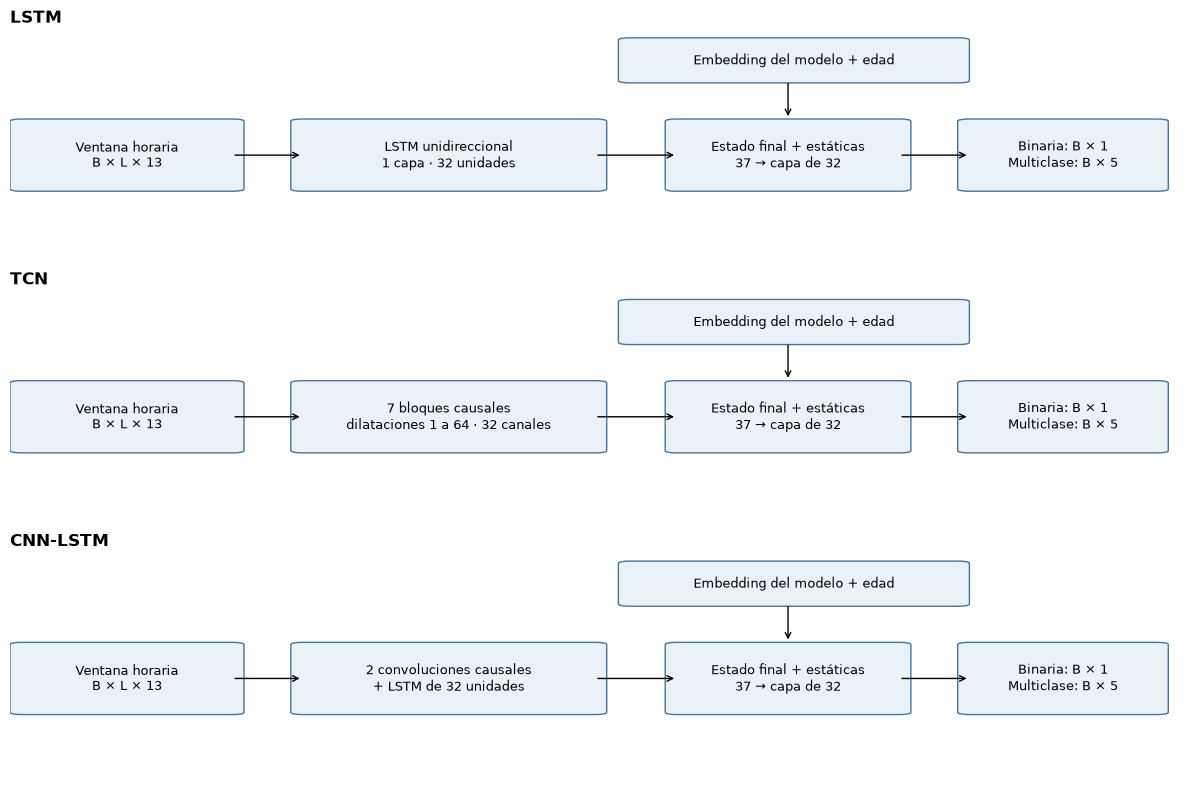

In [4]:
# Dibujar los esquemas dentro del notebook, sin guardar imágenes por separado.
fig, ejes = plt.subplots(3, 1, figsize=(12, 8))
descripciones = {
    "LSTM": "LSTM unidireccional\n1 capa · 32 unidades",
    "TCN": "7 bloques causales\ndilataciones 1 a 64 · 32 canales",
    "CNN-LSTM": "2 convoluciones causales\n+ LSTM de 32 unidades",
}
for eje, (nombre, detalle) in zip(ejes, descripciones.items()):
    eje.set_xlim(0, 1)
    eje.set_ylim(0, 1)
    eje.axis("off")
    eje.set_title(nombre, loc="left", fontweight="bold")
    cajas = [(0.01, 0.30, 0.18, 0.30, "Ventana horaria\nB × L × 13"),
             (0.25, 0.30, 0.25, 0.30, detalle),
             (0.57, 0.30, 0.19, 0.30, "Estado final + estáticas\n37 → capa de 32"),
             (0.82, 0.30, 0.16, 0.30, "Binaria: B × 1\nMulticlase: B × 5"),
             (0.53, 0.78, 0.28, 0.18, "Embedding del modelo + edad")]
    for x, y, ancho, alto, texto in cajas:
        caja = FancyBboxPatch((x, y), ancho, alto, boxstyle="round,pad=0.01",
                              facecolor="#eaf1f7", edgecolor="#49759a")
        eje.add_patch(caja)
        eje.text(x + ancho / 2, y + alto / 2, texto, ha="center", va="center", fontsize=9)
    for comienzo, fin in [(0.19, 0.25), (0.50, 0.57), (0.76, 0.82)]:
        eje.annotate("", xy=(fin, 0.45), xytext=(comienzo, 0.45), arrowprops={"arrowstyle": "->"})
    eje.annotate("", xy=(0.665, 0.61), xytext=(0.665, 0.78), arrowprops={"arrowstyle": "->"})
fig.tight_layout()
plt.show()

## 4. Definir la pérdida combinada y justificar sus pesos

Las dos tareas compartirán el codificador y parte de la cabeza. La pérdida será:

**pérdida total = 0.60 × pérdida binaria + 0.40 × pérdida multiclase.**

La binaria utiliza `BCEWithLogitsLoss`; la multiclase usa `CrossEntropyLoss`. Ambas promedian el lote. Se asigna 0.60 a la tarea principal de anticipar cualquier falla y 0.40 a identificar el componente, para que ambas influyan sin dejar de priorizar la tarea principal. Es una decisión inicial declarada, **no un valor elegido mirando prueba ni una ponderación demostrada como óptima**.

Los coeficientes no garantizan aportaciones iguales al gradiente: las pérdidas tienen escalas distintas. Por eso se registrarán por separado durante el entrenamiento y podremos revisar esta decisión usando únicamente entrenamiento y validación, dentro de un presupuesto explícito.

Esto no es lo mismo que ponderar clases por desbalance. El módulo admite pesos de clase opcionales, pero aquí la comprobación utiliza las pérdidas sin ponderación por clase. La comparación de pérdida ponderada y focal loss se hará en el siguiente paso, manteniendo el mismo criterio entre arquitecturas.

No se aplica sigmoid antes de la pérdida binaria ni softmax antes de la multiclase: esas operaciones ya se incluyen en las funciones de pérdida.

In [5]:
# Todas las arquitecturas comparten la misma ponderación inicial entre tareas.
criterio = PerdidaCombinada(peso_binaria=0.60)
display(pd.DataFrame({"tarea": ["Binaria", "Multiclase"],
                      "funcion": ["BCEWithLogitsLoss", "CrossEntropyLoss"],
                      "peso": [0.60, 0.40]}))

,tarea,funcion,peso
0,Binaria,BCEWithLogitsLoss,0.6
1,Multiclase,CrossEntropyLoss,0.4


## 5. Comprobar entradas, salidas y retropropagación

Seleccionaremos dos ejemplos de cada clase disponible de entrenamiento para tener un lote pequeño y variado. **Esta selección solo sirve para verificar el código**, no es una estrategia de muestreo para el entrenamiento final.

Probaremos cada red con las tres longitudes. Verificaremos formas, valores finitos y que las dos cabezas reciban gradientes. Calcularemos la retropropagación con `.backward()`, pero **no se ejecuta ningún optimizador ni se actualizan los parámetros**.

Las pérdidas de redes sin entrenar no permiten ordenar qué arquitectura es mejor: solo muestran que el cálculo es válido.

In [6]:
def obtener_lote_verificacion(longitud):
    """Crear un lote pequeño de entrenamiento con distintas clases para revisar la red."""
    tabla = anclas[longitud]["entrenamiento"]
    indices = []
    for clase in range(5):
        indices.extend(tabla.index[tabla["clase_codigo"] == clase][:2].tolist())
    subconjunto = Subset(datasets[longitud]["entrenamiento"], indices)
    cargador = DataLoader(subconjunto, batch_size=len(indices), shuffle=False, num_workers=0)
    return next(iter(cargador))


verificaciones = []
for longitud in LONGITUDES:
    lote = obtener_lote_verificacion(longitud)
    B = len(lote["modelo"])
    for nombre, modelo in modelos.items():
        modelo.train()
        modelo.zero_grad(set_to_none=True)
        salidas = modelo(lote["dinamicas"], lote["modelo"], lote["edad"])
        assert tuple(salidas["binaria"].shape) == (B, 1)
        assert tuple(salidas["multiclase"].shape) == (B, 5)
        assert torch.isfinite(salidas["binaria"]).all()
        assert torch.isfinite(salidas["multiclase"]).all()

        # Calcular ambas pérdidas y propagar el error, sin aplicar un paso de actualización.
        perdidas = criterio(salidas, lote)
        assert all(torch.isfinite(valor) for valor in perdidas.values())
        perdidas["total"].backward()
        for parametro in modelo.parameters():
            if parametro.grad is not None:
                assert torch.isfinite(parametro.grad).all()
        assert modelo.salida_binaria.weight.grad.abs().sum() > 0
        assert modelo.salida_multiclase.weight.grad.abs().sum() > 0
        verificaciones.append({"arquitectura": nombre, "L": longitud,
            "entrada": tuple(lote["dinamicas"].shape), "binaria": tuple(salidas["binaria"].shape),
            "multiclase": tuple(salidas["multiclase"].shape), "perdida_total_sin_entrenar": perdidas["total"].item(),
            "gradientes": "Correctos"})

display(pd.DataFrame(verificaciones).round(4))

,arquitectura,L,entrada,binaria,multiclase,perdida_total_sin_entrenar,gradientes
0,LSTM,24,"(10, 24, 13)","(10, 1)","(10, 5)",1.1009,Correctos
1,TCN,24,"(10, 24, 13)","(10, 1)","(10, 5)",1.0174,Correctos
2,CNN-LSTM,24,"(10, 24, 13)","(10, 1)","(10, 5)",1.0668,Correctos
3,LSTM,72,"(10, 72, 13)","(10, 1)","(10, 5)",1.0951,Correctos
4,TCN,72,"(10, 72, 13)","(10, 1)","(10, 5)",1.0973,Correctos
5,CNN-LSTM,72,"(10, 72, 13)","(10, 1)","(10, 5)",1.0650,Correctos
6,LSTM,168,"(10, 168, 13)","(10, 1)","(10, 5)",1.1033,Correctos
7,TCN,168,"(10, 168, 13)","(10, 1)","(10, 5)",1.1121,Correctos
8,CNN-LSTM,168,"(10, 168, 13)","(10, 1)","(10, 5)",1.0654,Correctos


Las **nueve combinaciones** de arquitectura y longitud funcionaron: cada lote de diez ejemplos produjo salidas de **10 × 1** y **10 × 5**, con pérdidas finitas y gradientes correctos en ambas cabezas.

Las pérdidas iniciales observadas están aproximadamente entre **1.02 y 1.11**, pero corresponden a parámetros sin entrenar, dropout activo y pequeños lotes de comprobación. **No se interpretan como desempeño ni se usan para elegir arquitectura.** No hubo pasos de optimización ni actualización de pesos.

## 6. Comprobar causalidad y conversión a probabilidades

Cambiar las horas posteriores a un punto de la ventana no debe alterar los estados anteriores del codificador. Esta prueba detecta un relleno simétrico incorrecto en las convoluciones o un procesamiento que consulte el futuro dentro de la secuencia.

Se usa modo evaluación para desactivar dropout y comparar exactamente las mismas operaciones. El estado final sí puede usar toda la ventana hasta `t`; la prueba no prohíbe utilizar ese pasado completo.

Para interpretar las salidas, sigmoid convierte el logit binario a un número entre 0 y 1; softmax convierte los cinco logits en probabilidades que suman uno. Antes del entrenamiento esas probabilidades **no deben usarse como alertas**.

In [7]:
# Usar una ventana real de entrenamiento y modificar solo su segunda mitad en una copia.
lote = obtener_lote_verificacion(168)
original = lote["dinamicas"][:2].clone()
corte = original.shape[1] // 2
modificada = original.clone()
modificada[:, corte:, :] = modificada[:, corte:, :] + 10.0
causalidad = []

for nombre, modelo in modelos.items():
    modelo.eval()
    with torch.no_grad():
        estados_originales = modelo.codificar_secuencia(original)
        estados_modificados = modelo.codificar_secuencia(modificada)

    # Si los codificadores son causales, el prefijo no cambia al modificar el sufijo.
    diferencia = (estados_originales[:, :corte, :] - estados_modificados[:, :corte, :]).abs().max().item()
    assert torch.allclose(estados_originales[:, :corte, :], estados_modificados[:, :corte, :], atol=1e-6)
    causalidad.append({"arquitectura": nombre, "maxima_diferencia_en_pasado": diferencia, "resultado": "Causal"})

display(pd.DataFrame(causalidad))

# Comprobar las probabilidades sin usarlas para evaluar desempeño ni elegir umbrales.
modelo = modelos["LSTM"]
with torch.no_grad():
    salidas = modelo(lote["dinamicas"], lote["modelo"], lote["edad"])
    probabilidad_falla = torch.sigmoid(salidas["binaria"])
    probabilidades_componentes = torch.softmax(salidas["multiclase"], dim=1)
assert ((probabilidad_falla >= 0) & (probabilidad_falla <= 1)).all()
assert torch.allclose(probabilidades_componentes.sum(dim=1), torch.ones(len(lote["modelo"])), atol=1e-6)
print("Probabilidades con formas y rangos correctos; sin evaluación predictiva.")

,arquitectura,maxima_diferencia_en_pasado,resultado
0,LSTM,0.0,Causal
1,TCN,0.0,Causal
2,CNN-LSTM,0.0,Causal


Probabilidades con formas y rangos correctos; sin evaluación predictiva.


Las tres redes obtuvieron una diferencia máxima de **0.0 en los estados anteriores** al cambiar la segunda mitad de una ventana de 168 horas. La prueba confirma el comportamiento causal de estas implementaciones para el ejemplo revisado.

Las conversiones a probabilidades también respetaron sus formas, rangos y suma multiclase. Las dos cabezas aún no están entrenadas y no se utilizan para emitir alertas ni calcular métricas de validación. La existencia de dos cabezas no obliga por sí sola a que la probabilidad binaria coincida exactamente con uno menos la probabilidad de `ninguno`; esa coherencia podrá revisarse al evaluar los modelos.

## 7. Qué comparación tenemos y qué falta

En este paso se implementaron y comprobaron las tres arquitecturas. Todas usan 13 canales, embedding de cuatro dimensiones, antigüedad, cabeza compartida de 32 unidades, dos salidas y la misma pérdida combinada. Conservan la longitud temporal y pueden recibir 24, 72 o 168 horas.

La comparación actual es **estructural y de funcionamiento**, no de calidad predictiva. No se ha calculado PR-AUC, recall o F1 de estas redes ni se ha elegido una ganadora. Los datos de validación permanecen disponibles, pero no se usaron en las comprobaciones de las redes.

**Siguiente paso:** entrenar y comparar usando early stopping por PR-AUC de validación, dropout y weight decay, presupuesto de búsqueda declarado y al menos dos tratamientos de desbalance. Se registrarán ambas pérdidas y la total; se estudiará también la longitud de ventana. Después se comparará contra la línea base y se medirá anticipación con alertas sostenidas. La elección final no dependerá de prueba.

### Reutilizar las arquitecturas

`Modelación/arquitecturas_secuenciales.py` contiene las tres redes y `PerdidaCombinada`. Una vez incluidas las carpetas de módulos en la ruta de importación, como en la primera celda:

```python
from arquitecturas_secuenciales import ModeloLSTM, PerdidaCombinada

modelo = ModeloLSTM(preparacion["numero_codigos_modelo"])
criterio = PerdidaCombinada(peso_binaria=0.60)
```

El módulo no ejecuta preparación ni entrenamiento al importarlo. Los próximos notebooks utilizarán estas mismas clases, sin copiar su implementación. Las redes de este notebook siguen sin entrenar: calcular gradientes no las ajusta si no se ejecuta un optimizador.

No se guardaron archivos auxiliares, no se modificaron los datos y no se hizo evaluación en prueba. 